# IS 4487 Assignment 11: Predicting Airbnb Prices with Regression

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using only the most impactful predictors
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## 1. Load Your Transformed Airbnb Dataset

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### Do the following:
- Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)
- Use `pandas` to load and preview the dataset


In [2]:

import pandas as pd

# Load the backup Airbnb dataset from GitHub
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/airbnb_listings.csv"

df = pd.read_csv(url)

# Check the dataset size
print("Dataset Shape:", df.shape)

# Preview the first 5 rows
df.head()


Dataset Shape: (459, 77)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,host_url,host_name,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2992450,https://www.airbnb.com/rooms/2992450,20250804133828,2025-08-04,city scrape,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,NaN,https://www.airbnb.com/users/show/4621559,Kenneth,...,4.56,3.22,3.67,NaN,0,1,1,0,0,0.07
1,3820211,https://www.airbnb.com/rooms/3820211,20250804133828,2025-08-04,city scrape,Funky Urban Gem: Prime Central Location - Park...,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.81,4.81,4.77,NaN,0,4,4,0,0,2.32
2,5651579,https://www.airbnb.com/rooms/5651579,20250804133828,2025-08-04,city scrape,Large studio apt by Capital Center & ESP@,"Spacious studio with hardwood floors, fully eq...",The neighborhood is very eclectic. We have a v...,https://www.airbnb.com/users/show/29288920,Gregg,...,4.88,4.76,4.64,NaN,0,2,1,1,0,2.97
3,6623339,https://www.airbnb.com/rooms/6623339,20250804133828,2025-08-04,city scrape,Bright & Cozy City Stay · Top Location + Parking!,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.70,4.80,4.72,NaN,0,4,4,0,0,2.68
4,9005989,https://www.airbnb.com/rooms/9005989,20250804133828,2025-08-04,city scrape,"Studio in The heart of Center SQ, in Albany NY",(21 years of age or older ONLY) NON- SMOKING.....,"There are many shops, restaurants, bars, museu...",https://www.airbnb.com/users/show/17766924,Sugey,...,4.93,4.87,4.77,NaN,0,1,1,0,0,5.67


### Reflection:
1. What business information does the dataset include?
2. How many rows and columns are present?

### ✍️ Your Response: 🔧
1. The dataset includes business information about Airbnb listings, such as property prices, locations, room types, host information, availability, and customer reviews. This information can help us understand what factors influence Airbnb prices.

2. The dataset contains 459 rows and 77 columns, representing 459 Airbnb listings and 77 different variables.

## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### Do the following:
- Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they’re still in your dataset

In [3]:
columns_to_drop = [
    'id', 'listing_url', 'scrape_id', 'last_scraped',
    'source', 'name', 'description',
    'neighborhood_overview', 'host_url',
    'host_name'
]

df = df.drop(columns=columns_to_drop, errors='ignore')

print("Updated Dataset Shape:", df.shape)
df.head()


Updated Dataset Shape: (459, 67)


,host_since,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2013-01-07,"New York, NY",I am a real down to earth & cool person.,NaN,NaN,50%,f,https://a0.muscache.com/im/users/4621559/profi...,https://a0.muscache.com/im/users/4621559/profi...,NaN,...,4.56,3.22,3.67,NaN,0,1,1,0,0,0.07
1,2014-08-07,"Albany, NY","Hello! I’m a proud resident of Albany, NY, whe...",within an hour,100%,100%,t,https://a0.muscache.com/im/pictures/user/User/...,https://a0.muscache.com/im/pictures/user/User/...,Center Square & Hudson/Park,...,4.81,4.81,4.77,NaN,0,4,4,0,0,2.32
2,2015-03-13,"Albany, NY",I am an Albany native .I have lived in Ireland...,within an hour,100%,99%,f,https://a0.muscache.com/im/users/29288920/prof...,https://a0.muscache.com/im/users/29288920/prof...,NaN,...,4.88,4.76,4.64,NaN,0,2,1,1,0,2.97
3,2014-08-07,"Albany, NY","Hello! I’m a proud resident of Albany, NY, whe...",within an hour,100%,100%,t,https://a0.muscache.com/im/pictures/user/User/...,https://a0.muscache.com/im/pictures/user/User/...,Center Square & Hudson/Park,...,4.70,4.80,4.72,NaN,0,4,4,0,0,2.68
4,2014-07-07,"Albany, NY",NaN,NaN,NaN,100%,t,https://a0.muscache.com/im/pictures/user/ae311...,https://a0.muscache.com/im/pictures/user/ae311...,NaN,...,4.93,4.87,4.77,NaN,0,1,1,0,0,5.67


### Reflection:
1. What columns did you drop, and why?
2. What risks might occur if you included them in your model?

### ✍️ Your Response: 🔧
1. I dropped columns such as listing ID, listing URL, scrape ID, listing name, description, and host name because they don’t provide useful numerical information for predicting Airbnb prices.

2. Including these columns could add unnecessary noise to the model and make it more complicated. Some variables, like listing IDs or host names, could also cause the model to identify patterns that don’t actually explain listing prices.

## 3. Explore Relationships Between Numeric Features

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### Do the following:
- Generate a correlation matrix
- Identify which variables are strongly related to `price`

Strongest Positive Correlations:
accommodates               0.579588
beds                       0.547032
bedrooms                   0.499286
bathrooms                  0.468030
estimated_revenue_l365d    0.249488
maximum_maximum_nights     0.122872
minimum_maximum_nights     0.112166
maximum_nights_avg_ntm     0.111271
availability_30            0.108409
availability_60            0.060509
Name: price, dtype: float64

Strongest Negative Correlations:
review_scores_communication   -0.131798
longitude                     -0.118913
review_scores_checkin         -0.103223
reviews_per_month             -0.090843
minimum_nights                -0.075122
minimum_minimum_nights        -0.066554
minimum_nights_avg_ntm        -0.065831
maximum_minimum_nights        -0.061523
number_of_reviews             -0.059924
estimated_occupancy_l365d     -0.049438
Name: price, dtype: float64


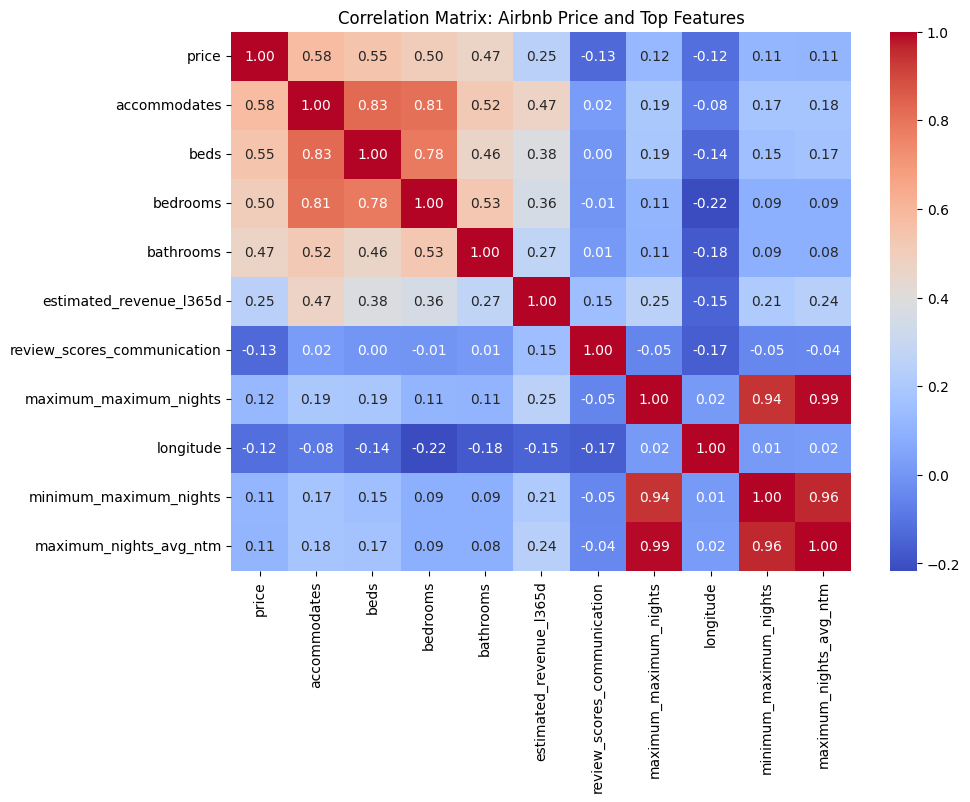

In [4]:
df['price'] = pd.to_numeric(
    df['price'].astype(str).str.replace('$', '', regex=False)
                            .str.replace(',', '', regex=False),
    errors='coerce'
)

numeric_df = df.select_dtypes(include='number')
correlation_matrix = numeric_df.corr()

price_correlations = correlation_matrix['price'].drop('price').dropna()

print("Strongest Positive Correlations:")
print(price_correlations.sort_values(ascending=False).head(10))

print("\nStrongest Negative Correlations:")
print(price_correlations.sort_values().head(10))

top_features = price_correlations.abs().sort_values(
    ascending=False
).head(10).index

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_matrix.loc[
        ['price'] + top_features.tolist(),
        ['price'] + top_features.tolist()
    ],
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('Correlation Matrix: Airbnb Price and Top Features')
plt.show()


### Reflection:
1. Which variables had the strongest positive or negative correlation with price?
2. Which variables might be useful predictors?

### ✍️ Your Response: 🔧
1. The strongest positive correlations with price were accommodates (0.58), beds (0.55), bedrooms (0.50), and bathrooms (0.47). This suggests that larger properties that can accommodate more guests tend to have higher prices. The strongest negative correlations were review scores for communication (-0.13) and longitude (-0.12), although these relationships were relatively weak.

2. I think accommodates, beds, bedrooms, and bathrooms would be useful predictors because they had the strongest correlations with price. These variables describe the size and capacity of a property, which makes sense because larger Airbnb listings generally cost more. I would focus on these features when building the regression model.

## 4. Define Features and Target Variable

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### Do the following:
- Set `price` as your target variable
- Remove `price` from your predictors

In [6]:
y = df['price']

X = df.select_dtypes(include='number').drop(
    columns=[
        'price',
        'estimated_revenue_l365d',
        'estimated_occupancy_l365d'
    ],
    errors='ignore'
)

print("Number of features:", X.shape[1])
print("Features:", X.columns.tolist())
print("Target variable:", y.name)


Number of features: 39
Features: ['host_listings_count', 'host_total_listings_count', 'latitude', 'longitude', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy', 'number_of_reviews_ly', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'license', 'instant_bookable', 'calculated_host_listings_count', 'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count_private_rooms', 'calculated_host_listings_count_shared_rooms', 'reviews_per_month']
Target variable: price


### Reflection:
1. What features are you using?
2. Why is this a regression problem and not a classification problem?

### ✍️ Your Response: 🔧
1. I am using numerical features such as accommodates, beds, bedrooms, bathrooms, availability, and review scores to predict Airbnb prices. I excluded price from the predictors because that is the variable we are trying to predict.

2. This is a regression problem because we are predicting a numerical value, which is the price of an Airbnb listing. Classification would be used if we were predicting categories, such as whether a listing is cheap, moderate, or expensive.

## 5. Split Data into Training and Testing Sets

### Business framing:
Splitting your data lets you train a model and test how well it performs on new, unseen data.

### Do the following:
- Use `train_test_split()` to split into 80% training, 20% testing



In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)


Training set: (367, 39)
Testing set: (92, 39)


## 6. Fit a Linear Regression Model

### Business framing:
Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### Do the following:
- Fit a linear regression model to your training data
- Use it to predict prices for the test set



In [9]:
train_valid = y_train.notna()
test_valid = y_test.notna()

X_train = X_train.loc[train_valid].copy()
y_train = y_train.loc[train_valid]

X_test = X_test.loc[test_valid].copy()
y_test = y_test.loc[test_valid]

train_medians = X_train.median()

X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

valid_columns = X_train.columns[X_train.notna().all()]
X_train = X_train[valid_columns]
X_test = X_test[valid_columns]

print("Clean training set:", X_train.shape)
print("Clean testing set:", X_test.shape)

model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred
})

results.head(10)



Clean training set: (367, 38)
Clean testing set: (92, 38)


,Actual Price,Predicted Price
124,93.0,94.126442
30,54.0,94.792689
199,59.0,148.694623
438,59.0,86.150790
154,102.0,75.901261
225,95.0,87.135308
405,65.0,62.479633
296,95.0,41.276619
222,95.0,97.505855
75,118.0,82.768756


## 7. Evaluate Model Performance

### Business framing:  
A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### Do the following:
- Print MSE and R² score for your model

In [10]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error (MSE):", round(mse, 2))
print("R² Score:", round(r2, 4))


Mean Squared Error (MSE): 8692.75
R² Score: -0.5488


### Reflection:
1. What is your R² score? How well does your model explain price variation?
2. Is your MSE large or small? What could you do to improve it?

### ✍️ Your Response: 🔧
1. My R squared score was -0.5488, which means the model does not explain Airbnb price variation very well on the test data. The negative score indicates that the model performed worse than simply predicting the average price.

2. My MSE was 8,692.75, which is relatively high and suggests that the model’s predictions have large errors. To improve it, I could remove unnecessary features, address outliers, and focus on variables that have stronger relationships with price.

## 8. Interpret Model Coefficients

### Business framing:
The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### Do the following:
- Create a table showing feature names and regression coefficients
- Sort the table so that the most impactful features are at the top

In [11]:
coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_
})

coefficients['Absolute Coefficient'] = coefficients['Coefficient'].abs()

coefficients = coefficients.sort_values(
    by='Absolute Coefficient',
    ascending=False
)

coefficients.head(15)


,Feature,Coefficient,Absolute Coefficient
2,latitude,-1137.680024,1137.680024
3,longitude,-525.807781,525.807781
29,review_scores_communication,-134.773625,134.773625
31,review_scores_value,127.836906,127.836906
28,review_scores_checkin,-88.212117,88.212117
11,maximum_minimum_nights,-37.330267,37.330267
14,minimum_nights_avg_ntm,36.204085,36.204085
5,bathrooms,35.498224,35.498224
27,review_scores_cleanliness,-27.304940,27.304940
7,beds,21.139810,21.139810


### Reflection:
1. Which features increased price the most?
2. Were any surprisingly negative?
3. What business insight could you draw from this?

### ✍️ Your Response: 🔧
1. Some of the largest positive coefficients were review scores for value 127.84, bathrooms 35.50, and beds 21.14. This suggests that higher value ratings and larger properties are associated with higher predicted prices when other variables are held constant.

2. I was surprised that bedrooms had a negative coefficient of -18.71, even though I expected more bedrooms to increase prices. Review scores for communication -134.77 were also surprisingly negative. This could be due to overlapping features or relationships within the dataset.

3. One business insight is that property size and guest ratings may help explain Airbnb prices. However, since the model performed poorly, Airbnb should improve the model before relying on these coefficients to make pricing recommendations.


## 9. Try to Improve the Linear Regression Model

### Business framing:
The first version of your model included all available features — but not all features are equally useful. Removing weak or noisy predictors can often improve performance and interpretation.

### Do the following:
1. Choose your top 3–5 features with the strongest absolute coefficients
2. Rebuild the regression model using just those features
3. Compare MSE and R² between the baseline and refined model

In [12]:
top_features = coefficients.head(5)['Feature'].tolist()

print("Selected Features:", top_features)

X_train_refined = X_train[top_features]
X_test_refined = X_test[top_features]

refined_model = LinearRegression()
refined_model.fit(X_train_refined, y_train)

y_pred_refined = refined_model.predict(X_test_refined)

refined_mse = mean_squared_error(y_test, y_pred_refined)
refined_r2 = r2_score(y_test, y_pred_refined)

comparison = pd.DataFrame({
    'Model': ['Baseline Model', 'Refined Model'],
    'Number of Features': [X_train.shape[1], len(top_features)],
    'MSE': [mse, refined_mse],
    'R²': [r2, refined_r2]
})

print(comparison.to_string(index=False))


Selected Features: ['latitude', 'longitude', 'review_scores_communication', 'review_scores_value', 'review_scores_checkin']
         Model  Number of Features        MSE        R²
Baseline Model                  38 8692.75365 -0.548821
 Refined Model                   5 6397.79798 -0.139920


### Reflection:
1. What features did you keep in the refined model, and why?
2. Did model performance improve? Why or why not?
3. Which model would you recommend to stakeholders?

### ✍️ Your Response: 🔧
1. I kept latitude, longitude, review scores for communication, review scores for value, and review scores for check-in because they had the strongest absolute coefficients in my original model.

2. Yes, the refined model performed better. The MSE decreased from 8,692.75 to 6,397.80, and the R squared improved from -0.5488 to -0.1399. This suggests that removing unnecessary features helped reduce prediction errors, although the model still needs improvement.

3. I would recommend the refined model because it uses fewer features and performs better than the original model. However, I would not recommend using it for actual pricing decisions yet because the R squared is still negative.

## 10. Reflect and Recommend

### Business framing:  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to Airbnb or its hosts?
3. What could you do next to improve this model or make it more useful?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response:
1. My model helped answer which factors influence Airbnb listing prices and whether we can use property information to predict how much a listing should cost. It also helped identify which variables have stronger relationships with price.

2. I would recommend that Airbnb hosts consider factors such as property size, guest capacity, location, and customer reviews when setting their prices. However, I would not recommend relying entirely on this model because its predictions were not accurate enough to make reliable pricing decisions.

3. I could improve the model by removing unnecessary variables, handling outliers, and including additional information such as property type and neighborhood. I could also experiment with other regression models to see if they provide more accurate predictions.

4. This assignment connects to my learning outcomes by showing me how data analytics can support business decisions while also considering ethics. As a Finance major, I want to understand how to use data responsibly and recognize when a model might not be reliable. This is important because inaccurate predictions could lead to poor financial decisions.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_11_regression.ipynb"